![Banner](../../../../Images/Banner/07_remote_sensing/09_12_surface_energy_balance_modeling.png)

# SSEBop, S-SEBI, the Triangle Method and PT-JPL

SEBAL and METRIC solve the aerodynamics of sensible heat at every pixel. A family of simpler models
skips that step. SSEBop places each pixel's temperature between a wet and a dry limit set by air
temperature and net radiation. S-SEBI and the triangle method read the limits from the scatter of
surface temperature against albedo or vegetation cover in the image itself. PT-JPL starts from the
Priestley-Taylor equation for potential ET and reduces it with plant and soil moisture constraints,
without a thermal band at all. Each makes different assumptions, and comparing them on the same
scene shows where they agree, where they disagree, and why combining several models, as OpenET
does, is attractive. This notebook runs all four on the 5 July 2024 scene, compares them with
METRIC, and builds a small ensemble with its spread.

## Overview

### SSEBop: operational simplified surface energy balance

Senay et al. (2013, 2023) define, for each pixel and day, a cold (wet) limit and a hot (dry) limit
of LST:

- Cold limit `Tc = c Tmax`, where `Tmax` is the daily maximum air temperature and `c` is calibrated
  as the typical ratio of LST to `Tmax` over well watered, dense vegetation (NDVI of at least 0.7).
- Hot limit `Th = Tc + dT`, where `dT = Rn rah / (rho cp)` is the temperature difference a dry,
  bare surface needs to carry the clear-sky daily net radiation `Rn` as sensible heat, with a fixed
  aerodynamic resistance of 110 s/m.

The ET fraction is the position of LST between the limits, `ETf = (Th - Ts) / dT`, clipped to 0 to
1.05, and actual ET is `ETa = ETf k ETref`. Because `dT` and `c` come from climate and the image,
SSEBop needs no anchor pixels and no wind, and it runs globally (USGS FEWS NET) and in OpenET.

### S-SEBI: simplified surface energy balance index

Roerink et al. (2000) observed that in an image with both wet and dry areas the scatter of LST
against albedo has a **dry edge** (the hottest LST at each albedo, decreasing at high albedo where
bright soil reflects much of the radiation) and a **wet edge** (the coolest LST, rising slowly with
albedo). With the two edges fitted as lines, `EF = (T_H - Ts) / (T_H - T_LE)`, where `T_H` and
`T_LE` are the dry and wet edge temperatures at the pixel's albedo. No weather data are needed for
the fraction.

### The triangle method

Jiang and Islam (2001) use the LST against fractional cover scatter. The dry edge gives the hottest
possible LST at each cover, the coolest pixels the wet limit. A Priestley-Taylor parameter `phi`
runs from `phi_max fc` at the dry edge to `phi_max = 1.26` at the wet limit, and
`EF = phi Delta / (Delta + gamma)`.

### PT-JPL

Fisher et al. (2008) start from the Priestley-Taylor equation,
`LE = alpha Delta / (Delta + gamma) (Rn - G)` with `alpha = 1.26`, and split it into canopy
transpiration, soil evaporation and interception, each reduced by constraints:

| Constraint | Formula | Meaning |
|---|---|---|
| `fwet` | `RH^4` | wet canopy fraction |
| `fg` | `fAPAR / fIPAR` | green fraction of the canopy |
| `fT` | `exp(-((Ta - Topt) / Topt)^2)` | temperature limit of photosynthesis |
| `fM` | `fAPAR / fAPARmax` | plant moisture |
| `fSM` | `RH^(VPD / beta)` | soil moisture from atmospheric dryness |

PT-JPL uses no thermal band: it sees water stress only through vegetation indices and the dryness
of the air. Over irrigated land in a dry climate this is its main weakness, because the air above
an irrigated field says little about the field's soil moisture.

### Ensembles

Each model's errors come from different assumptions, so their average is often more accurate than
any one of them. OpenET computes, for each pixel and month, the ensemble of its six models after
removing up to two outliers with the median absolute deviation (MAD) rule, and publishes the
ensemble mean together with each model.

## Simplified Models with GeoLattice

| Function | Model |
|---|---|
| `seb.cold_reference_temperature`, `seb.dt_from_climate`, `seb.run_ssebop` | SSEBop |
| `seb.ssebi` | S-SEBI: edges, EF and LE |
| `seb.triangle_method` | triangle: `phi`, EF and LE |
| `seb.priestley_taylor_jpl` | PT-JPL: canopy, soil and interception LE |
| `seb.fractional_cover` | vegetation cover from NDVI |

### Learning objectives

1. Explain the wet and dry limits of SSEBop, S-SEBI and the triangle method, and the constraints of
   PT-JPL.
2. Calibrate SSEBop's `c` factor and `dT` for a scene and map its ET fraction.
3. Fit the dry and wet edges of the albedo and LST scatter (S-SEBI) and of the cover and LST
   scatter (triangle).
4. Run PT-JPL and see what a model without a thermal band misses.
5. Put five models on a common footing, compare them by crop, and build an ensemble with an
   outlier rule and a spread map.

### Data

The 5 July 2024 Landsat 8 scene (`sd.load_scene`), its energy balance inputs (`sd.energy_inputs`),
ERA5 daily and overpass weather, and the METRIC result of notebook 06
(`outputs/metric_20240705.nc`, recomputed if missing).

### Contents

- Setup
- SSEBop
- S-SEBI
- The triangle method
- PT-JPL
- Five models on a common footing
- An ensemble and its spread
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

ds = sd.load_scene()  # Landsat 8, 5 July 2024
p = sd.energy_inputs(ds)  # NDVI, albedo, LST, Rn, G, reference ET
a = ds.attrs  # weather
ext = [float(ds.x.min()), float(ds.x.max()), float(ds.y.min()), float(ds.y.max())]  # map extent
path = OUT / "metric_20240705.nc"  # METRIC result of notebook 06
metric = xr.open_dataset(path).load() if path.exists() else sd.run_metric_scene(ds, p)  # read or recompute
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().select_dtypes("number").dropna()  # one row per pixel, numbers only
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## SSEBop

The `c` factor compares LST with the daily maximum air temperature over dense vegetation. `dT` uses
the clear-sky daily net radiation of a reference surface (albedo 0.23), computed as in FAO-56, and
the fixed resistance of 110 s/m.

c = 0.9760, Tc = 38.9 C | clear-sky Rn = 166 W/m2, dT = 16.7 K, Th = 55.7 C
pixels at ETf = 0 (hotter than Th): 32.0% | at the 1.05 cap: 5.9%


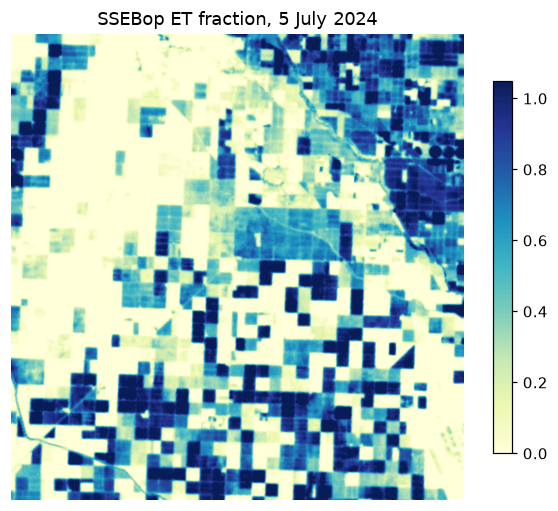

In [2]:
tmax_k = a["tmax_c"] + 273.15  # ERA5 daily maximum, K
tc, c = seb.cold_reference_temperature(p["lst"], p["ndvi"], tmax_k)  # cold limit and c factor
ra = float(seb.extraterrestrial_radiation_daily(sd.WESTSIDE["lat"], a["doy"]))  # MJ m-2 d-1
z = p["z"]; rso = (0.75 + 2e-5 * z) * ra  # clear-sky shortwave, MJ m-2 d-1
ea_d = float(seb.actual_vapour_pressure(t_dew_c=a["t_dew_daily_c"]))  # daily vapour pressure, kPa
rnl = 4.901e-9 * ((a["tmax_c"] + 273.16) ** 4 + (a["tmin_c"] + 273.16) ** 4) / 2 * (0.34 - 0.14 * ea_d ** 0.5)  # clear-sky net longwave
rn_cs = (0.77 * rso - rnl) / 0.0864  # clear-sky daily net radiation, W/m2
dT = seb.dt_from_climate(rn_cs, tmax_k, float(p["pressure"].mean()))  # hot - cold limit difference, K
ssebop = seb.run_ssebop(p["lst"], tc, dT, eto=p["etr_daily"], k=1.0)  # ETf and ETa with the alfalfa reference
print(f"c = {c:.4f}, Tc = {float(tc) - 273.15:.1f} C | clear-sky Rn = {rn_cs:.0f} W/m2, dT = {float(dT):.1f} K, Th = {float(tc + dT) - 273.15:.1f} C")  # limits
print(f"pixels at ETf = 0 (hotter than Th): {float((ssebop.etf == 0).mean()):.1%} | at the 1.05 cap: {float((ssebop.etf >= 1.05).mean()):.1%}")  # clipping
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(ssebop.etf, extent=ext, cmap="YlGnBu", vmin=0, vmax=1.05)  # ETf map
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("SSEBop ET fraction, 5 July 2024"); ax.axis("off"); plt.show()  # draw

SSEBop's limits come from the weather and a scene-wide `c`, not from two pixels. Here `c` is 0.976,
so the cold limit (38.9 C) is 3.7 K warmer than METRIC's cold anchor (35.2 C), and the hot limit
(55.7 C) is 4.3 K cooler than METRIC's hot anchor (60.0 C). The narrower range has two effects:
6 % of pixels, the coolest fields, reach the cap of 1.05, and 32 % of pixels, the hot fallow land
and rangeland, are hotter than the hot limit and get zero ET. SSEBop is run here with the alfalfa
reference and `k = 1` so that all models scale with the same reference; the operational SSEBop of
OpenET uses grass reference ET with a scaling factor.

## S-SEBI

`seb.ssebi` bins the albedo axis, takes the 99th and 1st percentile LST in each bin, fits the dry
edge to the bins above the albedo of the hottest bin and the wet edge below it, and returns EF.

dry edge T_H = 69.3 C + -35.9 albedo | wet edge T_LE = 37.4 C + -5.7 albedo


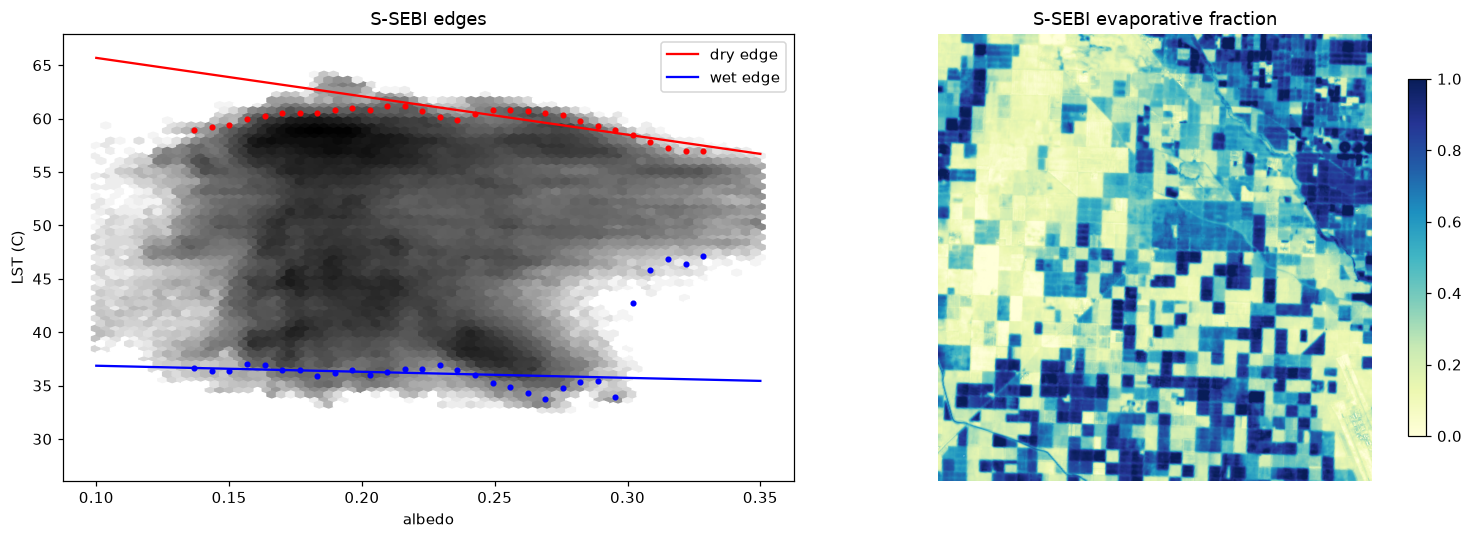

In [3]:
from io import StringIO  # read JSON text

ss = seb.ssebi(p["albedo"], p["lst"], p["rn"], p["g"], n_bins=30)  # S-SEBI
bins = pd.read_json(StringIO(ss.attrs["bins"]))  # the bins the edges were fitted to (stored as JSON)
print(f"dry edge T_H = {ss.attrs['a_dry'] - 273.15:.1f} C + {ss.attrs['b_dry']:.1f} albedo | wet edge T_LE = {ss.attrs['a_wet'] - 273.15:.1f} C + {ss.attrs['b_wet']:.1f} albedo")  # edges
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # scatter and map
ax[0].hexbin(p["albedo"].values.ravel(), (p["lst"] - 273.15).values.ravel(), gridsize=70, bins="log", cmap="Greys", extent=(0.1, 0.35, 28, 66))  # scatter
xx = np.linspace(0.1, 0.35, 50)  # albedo axis
ax[0].plot(xx, ss.attrs["a_dry"] - 273.15 + ss.attrs["b_dry"] * xx, "r-", label="dry edge"); ax[0].plot(xx, ss.attrs["a_wet"] - 273.15 + ss.attrs["b_wet"] * xx, "b-", label="wet edge")  # edges
ax[0].plot(bins.x, bins.y_max - 273.15, "r.", ms=6); ax[0].plot(bins.x, bins.y_min - 273.15, "b.", ms=6)  # bin percentiles
ax[0].set_xlabel("albedo"); ax[0].set_ylabel("LST (C)"); ax[0].legend(); ax[0].set_title("S-SEBI edges")  # labels
im = ax[1].imshow(ss.ef, extent=ext, cmap="YlGnBu", vmin=0, vmax=1); plt.colorbar(im, ax=ax[1], shrink=0.8); ax[1].set_title("S-SEBI evaporative fraction"); ax[1].axis("off")  # map
plt.tight_layout(); plt.show()  # draw

The scatter has the textbook shape: the hottest LST rises with albedo up to about 0.2 (darker
surfaces are hotter only when they are also dry) and then falls, as brighter surfaces reflect more
sunlight. The dry edge is fitted above that turning point (`T_H` falls by about 3.6 K per 0.1 of
albedo) and the wet edge below it, where it is almost flat near 36 to 37 C. Above an albedo of
0.3 there are no wet pixels, and the wet edge is an extrapolation. EF follows the irrigated
fields, but the wet edge is the coolest 1 % of every bin, so the method assumes some pixels at
every albedo are fully wet.

## The triangle method

dry edge Tmax(fc) = 61.9 C -17.7 fc | wet limit 35.8 C


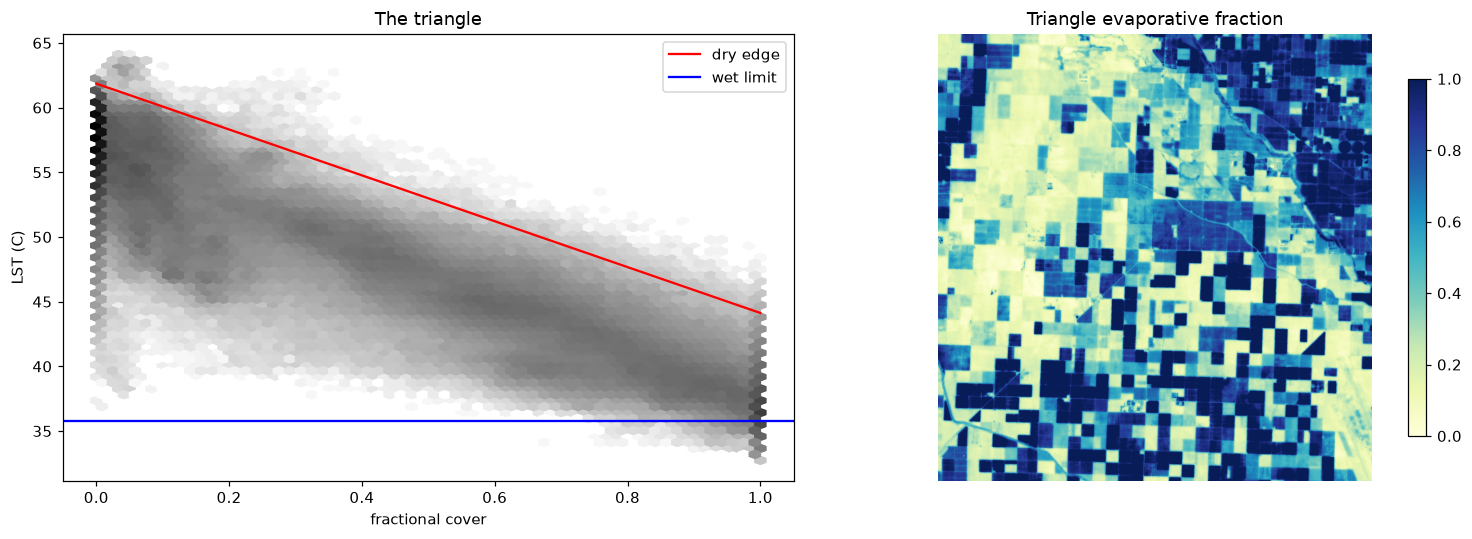

In [4]:
fc = seb.fractional_cover(p["ndvi"])  # fractional cover from NDVI (0.15 bare, 0.85 full)
tri = seb.triangle_method(fc, p["lst"], p["rn"], p["g"], a["t_air_c"] + 273.15, float(p["pressure"].mean()), n_bins=30)  # triangle
print(f"dry edge Tmax(fc) = {tri.attrs['a_dry'] - 273.15:.1f} C {tri.attrs['b_dry']:+.1f} fc | wet limit {tri.attrs['t_wet'] - 273.15:.1f} C")  # edges
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # scatter and map
ax[0].hexbin(fc.values.ravel(), (p["lst"] - 273.15).values.ravel(), gridsize=60, bins="log", cmap="Greys")  # scatter
ax[0].plot([0, 1], [tri.attrs["a_dry"] - 273.15, tri.attrs["a_dry"] + tri.attrs["b_dry"] - 273.15], "r-", label="dry edge")  # dry edge
ax[0].axhline(tri.attrs["t_wet"] - 273.15, color="b", label="wet limit"); ax[0].legend()  # wet limit
ax[0].set_xlabel("fractional cover"); ax[0].set_ylabel("LST (C)"); ax[0].set_title("The triangle")  # labels
im = ax[1].imshow(tri.ef, extent=ext, cmap="YlGnBu", vmin=0, vmax=1); plt.colorbar(im, ax=ax[1], shrink=0.8); ax[1].set_title("Triangle evaporative fraction"); ax[1].axis("off")  # map
plt.tight_layout(); plt.show()  # draw

The scatter shows the classic triangle, with a dry edge falling from about 60 C over bare soil
toward the wet limit at full cover. The ceiling of `EF = phi Delta / (Delta + gamma)` is
`1.26 Delta / (Delta + gamma)`, about 1.0 at the air temperature of this day, so the triangle cannot
represent fields that draw heat from the air either.

## PT-JPL

PT-JPL needs net radiation, NDVI, SAVI (with the usual `L = 0.5`), air temperature, vapour pressure
and pressure. The optimum temperature for growth `Topt` is set to 25 C here; Fisher et al. derive it
for each pixel from the climatology of the vegetation.

In [5]:
savi05 = seb.savi(p["sr"].red, p["sr"].nir, L=0.5)  # SAVI with L = 0.5
pt = seb.priestley_taylor_jpl(p["rn"], p["ndvi"], savi05, a["t_air_c"], a["ea_kpa"], float(p["pressure"].mean()), g=p["g"], topt_c=25.0)  # PT-JPL
es = float(seb.saturation_vapour_pressure(a["t_air_c"]))  # kPa
rh = a["ea_kpa"] / es  # relative humidity at the overpass
print(f"RH {rh:.2f}, VPD {es - a['ea_kpa']:.2f} kPa -> fwet = {rh ** 4:.5f}, fSM = {rh ** ((es - a['ea_kpa']) / 1.0):.5f}; "
      f"fT = {np.exp(-((a['t_air_c'] - 25) / 25) ** 2):.2f}")  # the atmospheric constraints
by_group(LE_canopy=pt.le_c, LE_soil=pt.le_s, LE_interception=pt.le_i, LE_total=pt.le, LE_metric=metric.le).round(0)  # per crop group

RH 0.10, VPD 6.62 kPa -> fwet = 0.00008, fSM = 0.00000; fT = 0.70


,LE_canopy,LE_soil,LE_interception,LE_total,LE_metric
Tree crops,90.0,0.0,0.0,90.0,425.0
Grapes,161.0,0.0,0.0,161.0,499.0
Annual crops,136.0,0.0,0.0,136.0,388.0
Fallow,3.0,0.0,0.0,3.0,104.0
Grass and shrubs,14.0,0.0,0.0,14.0,157.0
Developed,18.0,0.0,0.0,18.0,245.0


With 9 % relative humidity and a vapour pressure deficit above 6 kPa, PT-JPL's soil moisture
constraint `fSM` is essentially zero, so soil evaporation vanishes everywhere, including under
irrigated orchards whose wetted soil does evaporate. Canopy transpiration is limited by the
temperature constraint (40 C against an optimum of 25 C) and by `fM`. The model has no way to tell
an irrigated field from a dry one except through its greenness, and it gives much less LE than
METRIC over the crops.

## Five models on a common footing

The models differ in two ways at once: how they estimate the instantaneous energy partition, and
how they scale it to a day (METRIC and SSEBop with reference ET; S-SEBI, the triangle and PT-JPL
with net radiation or EF). To compare the first part alone, every model's instantaneous LE is
turned into a reference ET fraction, `ET_inst / ETr_inst`, and scaled with the same daily alfalfa
reference ET. SSEBop's daily ETf is used directly.

In [6]:
lam = seb.latent_heat_of_vaporization(p["lst"])  # J/kg
to_etrf = lambda le: (3600 * le / lam / p["etr_inst"]).clip(0, 1.3)  # instantaneous LE -> ETrF
fractions = {"METRIC": metric.etrf, "SSEBop": ssebop.etf, "S-SEBI": to_etrf(ss.le), "Triangle": to_etrf(tri.le), "PT-JPL": to_etrf(pt.le)}  # one fraction per model
daily = xr.concat([f * p["etr_daily"] for f in fractions.values()], dim=pd.Index(list(fractions), name="model"))  # daily ET, mm
ra24 = float(seb.extraterrestrial_radiation_daily(sd.WESTSIDE["lat"], a["doy"])) * 1e6 / 86400  # W/m2
rn24 = seb.daily_net_radiation(a["rs_daily_mj"] * 1e6 / 86400, p["albedo"], ra24=ra24)  # 24 h net radiation, W/m2
native = {"S-SEBI": seb.instantaneous_to_daily(ss.ef, method="ef", rn24=rn24)}  # S-SEBI with its own EF scaling
tab = pd.concat({m: by_group(et=daily.sel(model=m)).et for m in fractions}, axis=1)  # mean daily ET per crop group and model
tab["S-SEBI, EF x Rn24"] = by_group(et=native["S-SEBI"]).et  # S-SEBI with its native scaling, for contrast
tab.round(2)  # mm/day

,METRIC,SSEBop,S-SEBI,Triangle,PT-JPL,"S-SEBI, EF x Rn24"
Tree crops,10.73,7.70,7.17,8.32,2.27,4.05
Grapes,12.57,10.65,8.50,10.41,4.06,4.52
Annual crops,9.78,8.26,6.82,8.06,3.41,3.61
Fallow,2.72,0.27,1.63,1.61,0.08,1.26
Grass and shrubs,4.12,1.21,2.12,2.61,0.35,1.55
Developed,6.24,2.83,3.32,3.80,0.45,2.26


,METRIC,SSEBop,S-SEBI,Triangle,PT-JPL
METRIC,1.00,0.94,0.95,0.97,0.81
SSEBop,0.94,1.00,0.98,0.98,0.90
S-SEBI,0.95,0.98,1.00,0.99,0.89
Triangle,0.97,0.98,0.99,1.00,0.90
PT-JPL,0.81,0.90,0.89,0.90,1.00


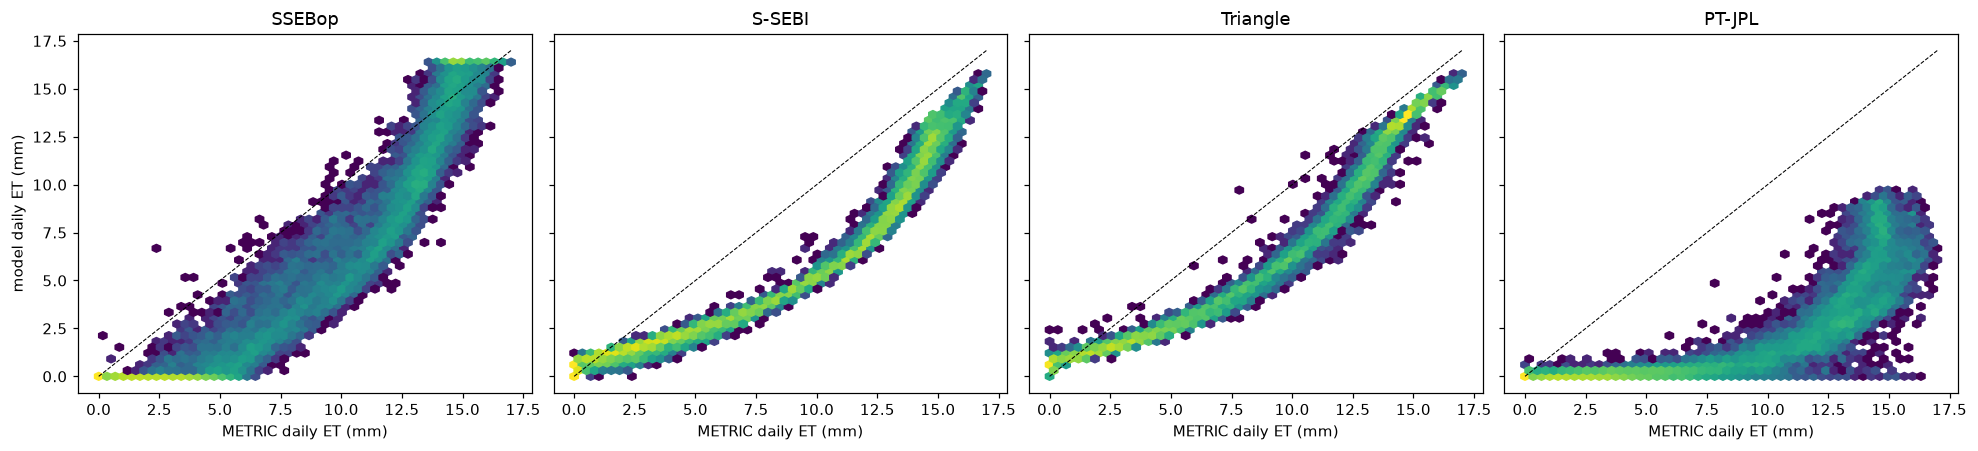

In [7]:
flat = daily.stack(pix=("y", "x")).dropna("pix").transpose("pix", "model")  # pixels with every model
samp = flat.isel(pix=np.random.default_rng(0).choice(flat.sizes["pix"], 20000, replace=False))  # sample for plotting
r = pd.DataFrame(np.corrcoef(flat.values.T), index=list(fractions), columns=list(fractions))  # correlation between models
display(r.round(2))  # agreement in pattern
fig, ax = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)  # four scatters
for a_, m in zip(ax, ["SSEBop", "S-SEBI", "Triangle", "PT-JPL"]):  # every other model
    a_.hexbin(samp.sel(model="METRIC"), samp.sel(model=m), gridsize=50, bins="log", extent=(0, 17, 0, 17)); a_.plot([0, 17], [0, 17], "k--", lw=0.7)  # vs METRIC
    a_.set_xlabel("METRIC daily ET (mm)"); a_.set_title(m)  # labels
ax[0].set_ylabel("model daily ET (mm)"); plt.tight_layout(); plt.show()  # draw

The thermal models (METRIC, SSEBop, S-SEBI and the triangle) agree closely on the spatial pattern,
with correlations of 0.94 to 0.99, because all of them read the same LST contrast. They disagree on
the level. METRIC is highest for every group, because its cold anchor is allowed to draw heat from
the air; S-SEBI and the triangle cap the fraction near `Rn - G` and give 1.5 to 3.5 mm less over
the crops; SSEBop sits between them over crops and near zero over fallow land, where its narrow
limits put many pixels at zero. PT-JPL has the weakest correlation (0.81 to 0.90) and by far the
lowest values, as expected for a model without a thermal band in a scene where water, not
greenness, separates the fields. The last column shows that S-SEBI's native daily scaling (EF times
`Rn24`) roughly halves its daily ET over the crops compared with the same fraction scaled with
reference ET, the same contrast as between SEBAL and METRIC in notebook 06.

## An ensemble and its spread

The ensemble follows the OpenET idea: at each pixel, models further than two scaled median absolute
deviations from the median are dropped, and the rest are averaged. The spread (range of the
remaining models) shows where the models disagree.

share of pixels where each model is dropped: {'METRIC': 21.1, 'SSEBop': 2.6, 'S-SEBI': 2.0, 'Triangle': 4.6, 'PT-JPL': 50.1}


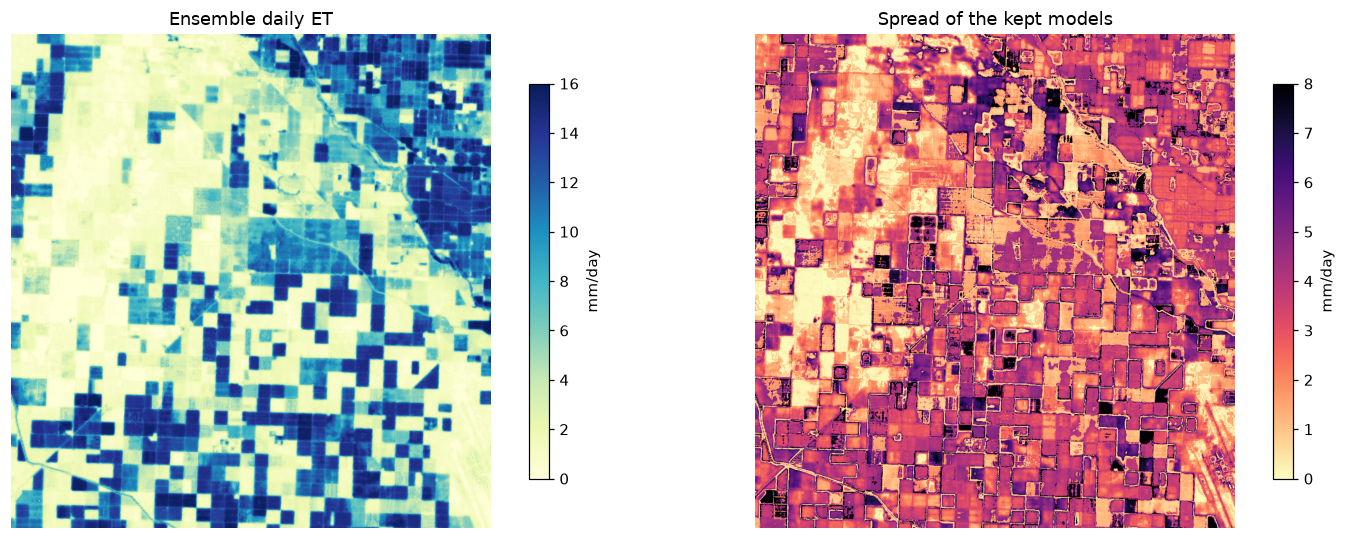

,ensemble,spread,metric
Tree crops,7.95,3.10,10.73
Grapes,10.22,4.20,12.57
Annual crops,7.86,3.61,9.78
Fallow,1.26,2.39,2.72
Grass and shrubs,2.06,2.60,4.12
Developed,3.44,3.00,6.24


In [8]:
med = daily.median("model")  # per-pixel median, mm
mad = 1.4826 * np.abs(daily - med).median("model")  # scaled median absolute deviation
keep = np.abs(daily - med) <= np.maximum(2 * mad, 0.25)  # drop models far from the median (0.25 mm floor for near-identical values)
ens = daily.where(keep).mean("model").rename("ensemble")  # ensemble mean
spread = (daily.where(keep).max("model") - daily.where(keep).min("model")).rename("spread")  # range of the kept models
dropped = (~keep & daily.notnull()).sum(["y", "x"]) / daily.notnull().sum(["y", "x"])  # how often each model is an outlier
print("share of pixels where each model is dropped:", (100 * dropped.to_series()).round(1).to_dict())  # outlier rates
fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # two maps
im = ax[0].imshow(ens, extent=ext, cmap="YlGnBu", vmin=0, vmax=16); plt.colorbar(im, ax=ax[0], shrink=0.8, label="mm/day"); ax[0].set_title("Ensemble daily ET"); ax[0].axis("off")  # ensemble
im = ax[1].imshow(spread, extent=ext, cmap="magma_r", vmin=0, vmax=8); plt.colorbar(im, ax=ax[1], shrink=0.8, label="mm/day"); ax[1].set_title("Spread of the kept models"); ax[1].axis("off")  # spread
plt.tight_layout(); plt.show()  # draw
xr.Dataset({"ensemble": ens, "spread": spread, "models": daily}).to_netcdf(OUT / "ensemble_20240705.nc", encoding={v: {"zlib": True, "complevel": 4} for v in ["ensemble", "spread", "models"]})  # saved for notebook 11, compressed
by_group(ensemble=ens, spread=spread, metric=daily.sel(model="METRIC")).round(2)  # per crop group

PT-JPL is dropped at half of the pixels, because it departs most from the thermal models over
irrigated land, and METRIC at a fifth of them, mostly over the crops where it is the only model that
represents advection. The ensemble is therefore 2 to 3 mm below METRIC over the crops. That is the
cost and the strength of an ensemble: it is robust to one model's error, but it also averages away
a process (advection) that only one model represents. The spread of the kept models is smallest over
fallow land (about 2.4 mm) and largest over grapes and annual crops (3.6 to 4.2 mm). A large spread
is a warning that a single model's value there is uncertain; notebook 11 asks which models are
closer to independent estimates.

## Summary and exercises

- SSEBop sets its wet and dry limits from `Tmax` and clear-sky net radiation (here `c` = 0.976 and
  `dT` = 16.7 K) and needs no anchors or wind; its narrow range put 32 % of pixels at zero ET.
- S-SEBI and the triangle read their limits from the image scatter; their fraction cannot exceed
  about `Rn - G`.
- PT-JPL has no thermal input; on this very dry day its soil moisture constraint removed soil
  evaporation everywhere and it gave much less ET than the thermal models over irrigated crops.
- The thermal models agree on the spatial pattern (correlations 0.94 to 0.99) and differ in level;
  METRIC is highest over crops, and the daily scaling (reference ET or net radiation) roughly halves
  or doubles daily ET by itself.
- An OpenET-style ensemble with a MAD outlier rule dropped PT-JPL at half of the pixels and METRIC at
  a fifth; its spread map shows where a single model is least reliable.

**Exercises**

1. Run SSEBop with the grass reference (`p["eto_daily"]`) and `k = 1.25`. How close is it to the
   run with the alfalfa reference?
2. Replace `Topt = 25` in PT-JPL with 35 C. How much of PT-JPL's gap to METRIC does the temperature
   constraint explain?
3. Fit the S-SEBI edges only on pixels with NDVI below 0.4. What happens to EF over orchards?
4. Add the SEBAL result of notebook 05 (scaled with reference ET) to the ensemble. Is it dropped as
   an outlier?